In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.feature_selection import (
    SelectKBest,
    f_classif,
    mutual_info_classif
)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report


In [2]:
!pip install ucimlrepo

In [3]:
from ucimlrepo import fetch_ucirepo

# Fetch Adult Income Dataset
adult = fetch_ucirepo(id=2)

# Separate features and target
X = adult.data.features
y = adult.data.targets

# Combine into one DataFrame
df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (48842, 15)


In [6]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [8]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [9]:
#check missing values
print(df.isnull().sum())

age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64


In [10]:
#Identify numerical and categorical features
numerical_features = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = df.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical Features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country', 'income']


In [11]:
# Handle missing values and clean the data
# Replace question marks with NaN
df = df.replace('?', np.nan)

# Check missing values
print(df.isnull().sum())

age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
dtype: int64


In [12]:
#Remove duplicate records
print("Duplicate records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate records: 29
Shape after removing duplicates: (48813, 15)


In [13]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [14]:
#Calculating corelation
# Select numerical columns
numerical_df = df.select_dtypes(include=['int64', 'float64'])

# Calculate correlation
correlation_matrix = numerical_df.corr()

# Display correlation matrix
correlation_matrix

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
age,1.000000,-0.076474,0.030760,0.077221,0.056908,0.071322
fnlwgt,-0.076474,1.000000,-0.038798,-0.003713,-0.004375,-0.013516
education-num,0.030760,-0.038798,1.000000,0.125186,0.080969,0.143872
capital-gain,0.077221,-0.003713,0.125186,1.000000,-0.031460,0.082154
capital-loss,0.056908,-0.004375,0.080969,-0.031460,1.000000,0.054440
hours-per-week,0.071322,-0.013516,0.143872,0.082154,0.054440,1.000000


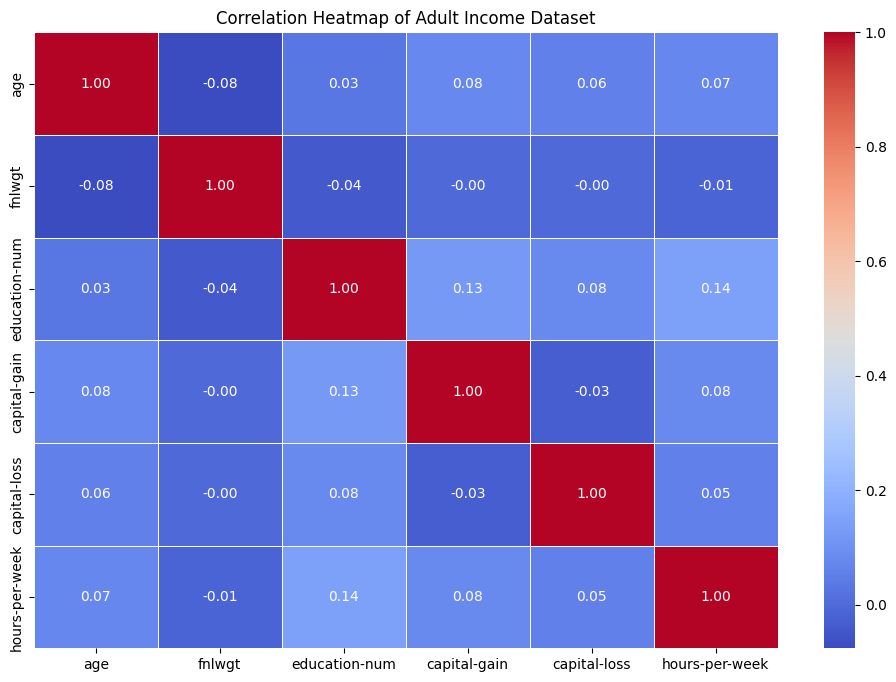

In [15]:
#Visualizing the corelation using heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Adult Income Dataset")
plt.show()

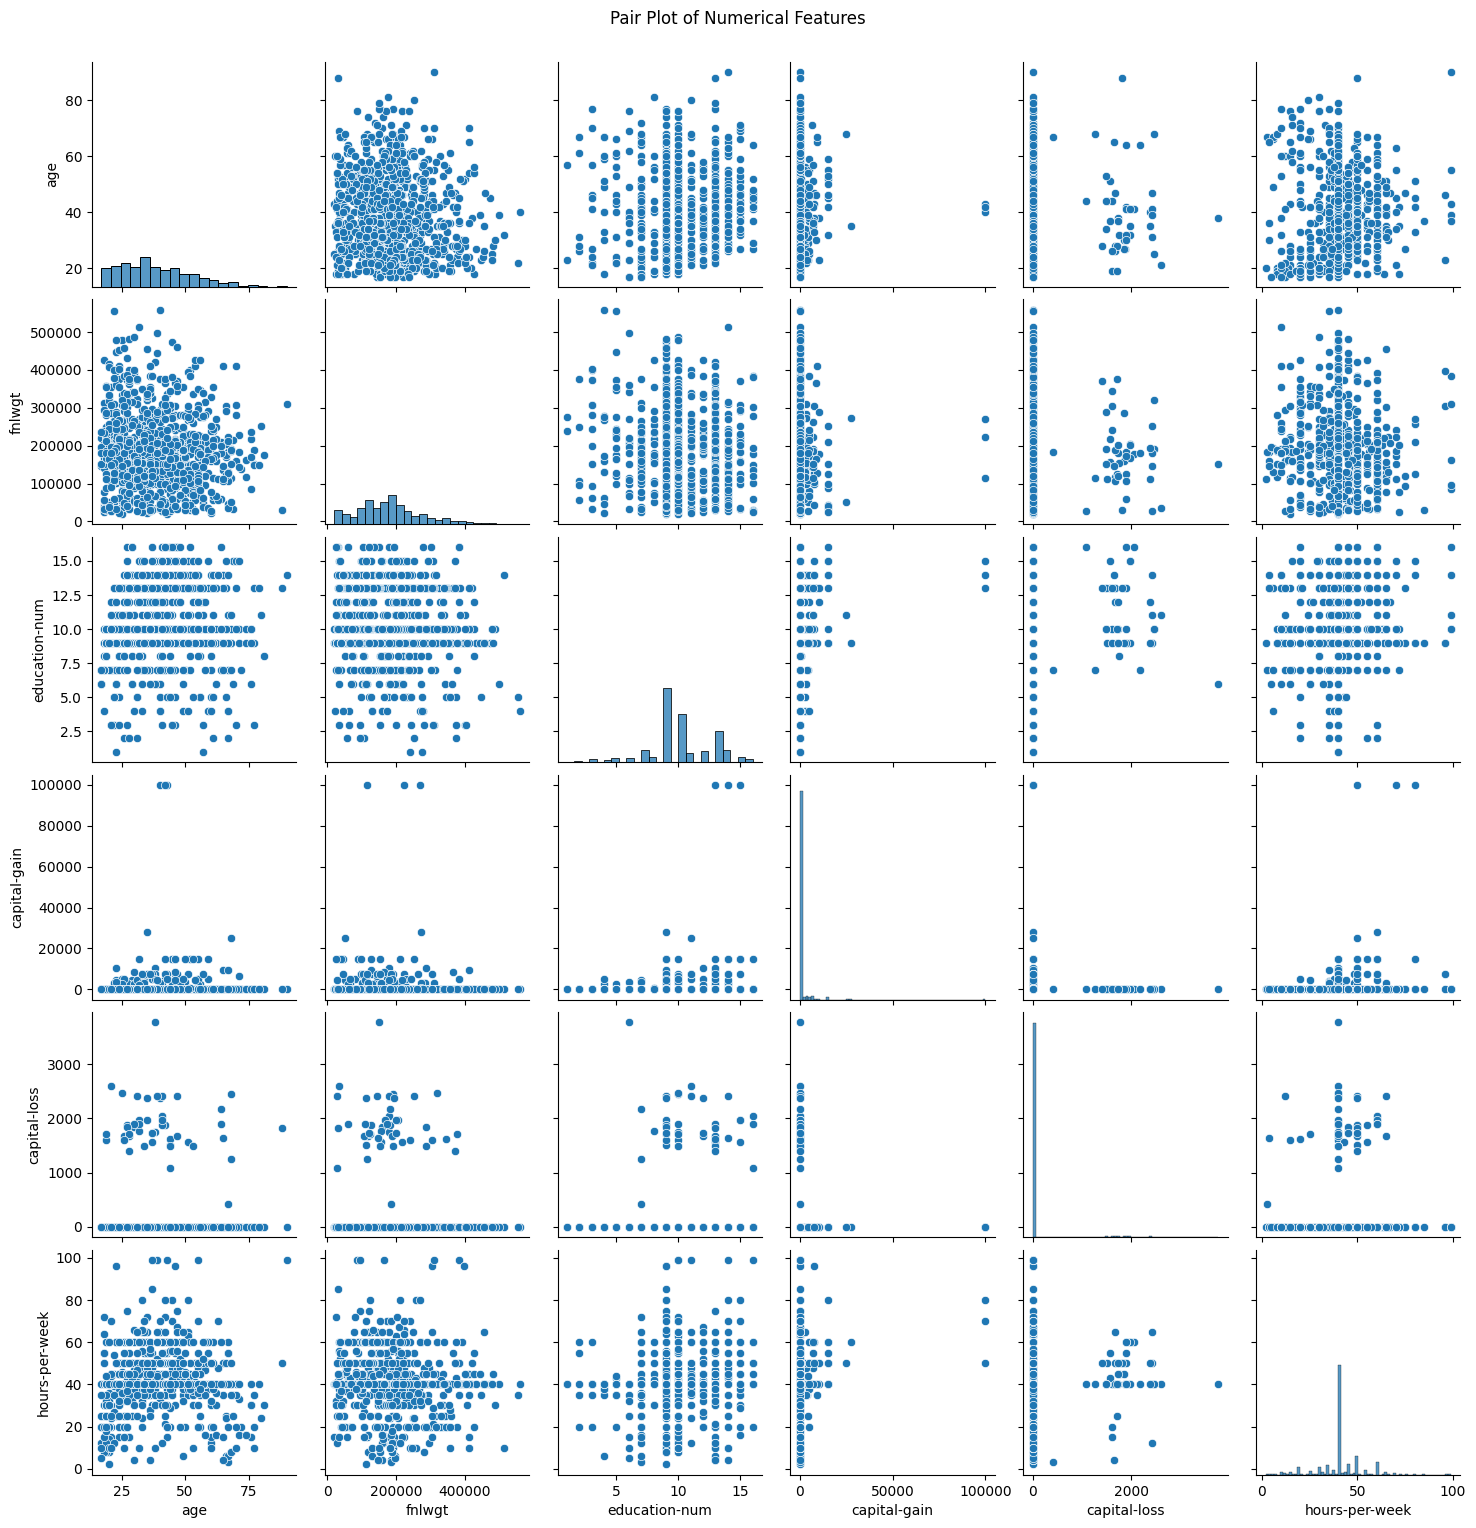

In [18]:
#Creating a pairplot / scatter plot
sns.pairplot(
    numerical_df.sample(min(1000, len(numerical_df))),
    diag_kind='hist'
)

plt.suptitle("Pair Plot of Numerical Features", y=1.02)

plt.show()

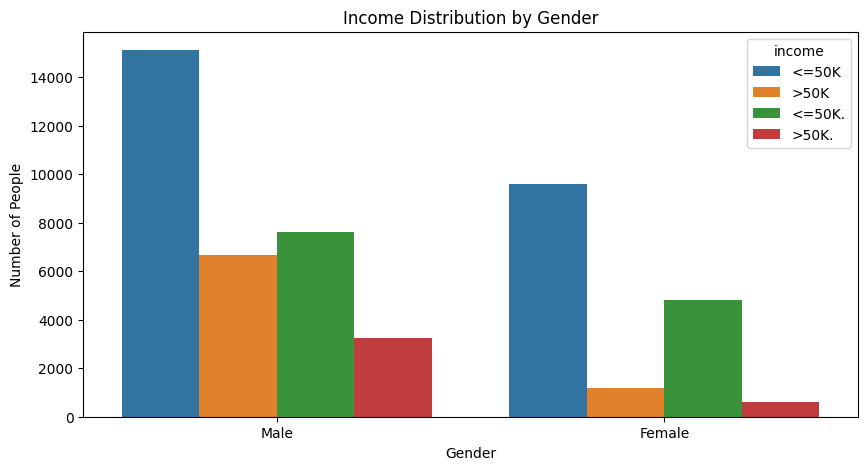

In [21]:
#Visualizng categorical features
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='sex',
    hue='income'
)

plt.title("Income Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of People")

plt.show()

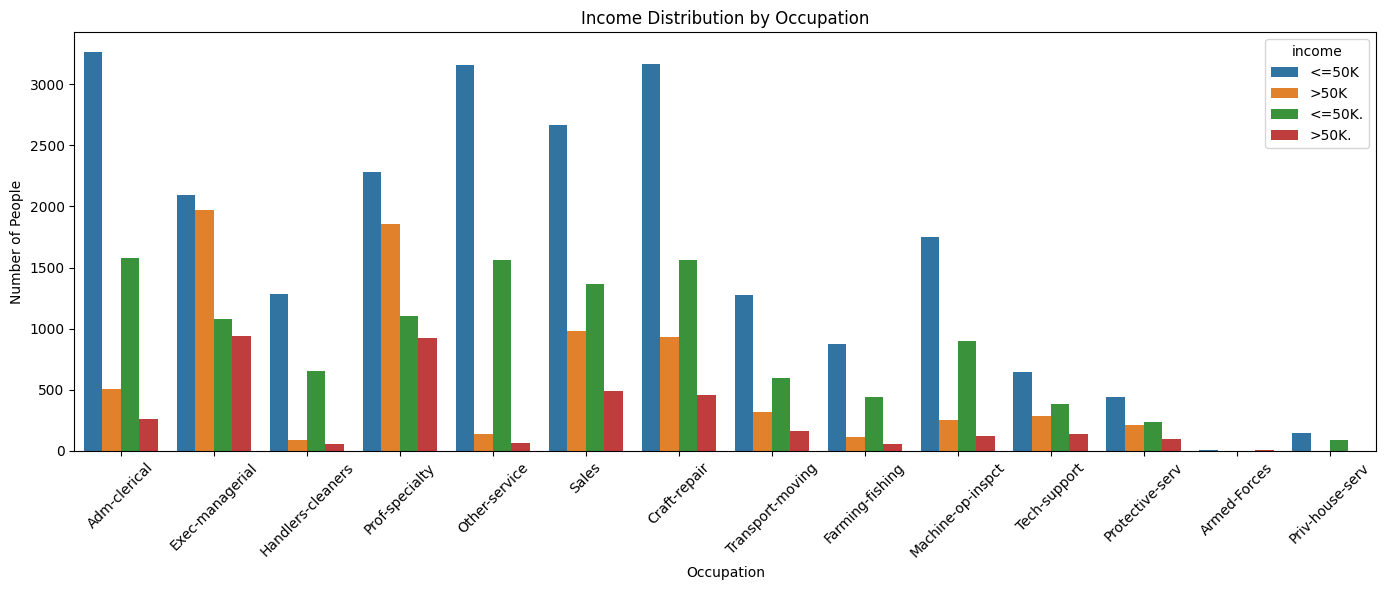

In [20]:
plt.figure(figsize=(14, 6))

sns.countplot(
    data=df,
    x='occupation',
    hue='income'
)

plt.title("Income Distribution by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Number of People")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [22]:
# Separate features and target
X = df.drop('income', axis=1)
y = df['income']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (48813, 14)
Target Shape: (48813,)


In [23]:
#Clean the target variable , The income column may contain spaces or punctuation around its category names.
y = y.astype(str).str.strip().str.replace('.', '', regex=False)

print(y.value_counts())

income
<=50K    37128
>50K     11685
Name: count, dtype: int64


In [24]:
#Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical Features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [26]:
#Split the data into training and testing data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (39050, 14)
Testing Data: (9763, 14)


In [27]:
#Preprocess the data , transform categorical data into numerical values
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing setup completed!")

Preprocessing setup completed!


In [28]:
#Usinng logistic regression and training the model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create baseline model
baseline_model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train the model
baseline_model.fit(X_train, y_train)

# Make predictions
y_pred = baseline_model.predict(X_test)

# Calculate accuracy
baseline_accuracy = accuracy_score(y_test, y_pred)

print("Baseline Model Accuracy:",
      round(baseline_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Baseline Model Accuracy: 85.32 %

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      7426
        >50K       0.74      0.60      0.66      2337

    accuracy                           0.85      9763
   macro avg       0.81      0.77      0.78      9763
weighted avg       0.85      0.85      0.85      9763



In [30]:
#Feature selection
from sklearn.feature_selection import SelectKBest, f_classif

# Create model with feature selection
anova_model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('selection', SelectKBest(score_func=f_classif, k=20)),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train model
anova_model.fit(X_train, y_train)

# Predict
anova_pred = anova_model.predict(X_test)

# Calculate accuracy
anova_accuracy = accuracy_score(y_test, anova_pred)

print("ANOVA Feature Selection Accuracy:",
      round(anova_accuracy * 100, 2), "%")

ANOVA Feature Selection Accuracy: 84.76 %


In [31]:
#Apply Mutual Information feature selection , another feature selection method
from sklearn.feature_selection import mutual_info_classif

# Create model with Mutual Information
mi_model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('selection', SelectKBest(
        score_func=lambda X, y: mutual_info_classif(
            X, y, random_state=42
        ),
        k=20
    )),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train model
mi_model.fit(X_train, y_train)

# Predict
mi_pred = mi_model.predict(X_test)

# Calculate accuracy
mi_accuracy = accuracy_score(y_test, mi_pred)

print("Mutual Information Accuracy:",
      round(mi_accuracy * 100, 2), "%")

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/cluster/_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.1

Mutual Information Accuracy: 84.58 %


In [33]:
#Identify the selected features
# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Get selected features from ANOVA
anova_selected = feature_names[
    anova_model.named_steps['selection'].get_support()
]

# Get selected features from Mutual Information
mi_selected = feature_names[
    mi_model.named_steps['selection'].get_support()
]

print("ANOVA Selected Features:")
print(anova_selected)

print("\nMutual Information Selected Features:")
print(mi_selected)

ANOVA Selected Features:
['num__age' 'num__education-num' 'num__capital-gain' 'num__capital-loss'
 'num__hours-per-week' 'cat__workclass_Self-emp-inc'
 'cat__education_Bachelors' 'cat__education_HS-grad'
 'cat__education_Masters' 'cat__education_Prof-school'
 'cat__marital-status_Married-civ-spouse'
 'cat__marital-status_Never-married' 'cat__occupation_Exec-managerial'
 'cat__occupation_Other-service' 'cat__relationship_Husband'
 'cat__relationship_Not-in-family' 'cat__relationship_Own-child'
 'cat__relationship_Unmarried' 'cat__sex_Female' 'cat__sex_Male']

Mutual Information Selected Features:
['num__age' 'num__fnlwgt' 'num__education-num' 'num__capital-gain'
 'num__capital-loss' 'num__hours-per-week' 'cat__education_Bachelors'
 'cat__education_Masters' 'cat__education_Prof-school'
 'cat__marital-status_Divorced' 'cat__marital-status_Married-civ-spouse'
 'cat__marital-status_Never-married' 'cat__occupation_Exec-managerial'
 'cat__occupation_Other-service' 'cat__relationship_Husband'


In [34]:
#Compare model performance
results = pd.DataFrame({
    'Model': [
        'All Features',
        'ANOVA',
        'Mutual Information'
    ],
    'Accuracy': [
        baseline_accuracy * 100,
        anova_accuracy * 100,
        mi_accuracy * 100
    ]
})

print(results)

                Model   Accuracy
0        All Features  85.322135
1               ANOVA  84.758783
2  Mutual Information  84.584656


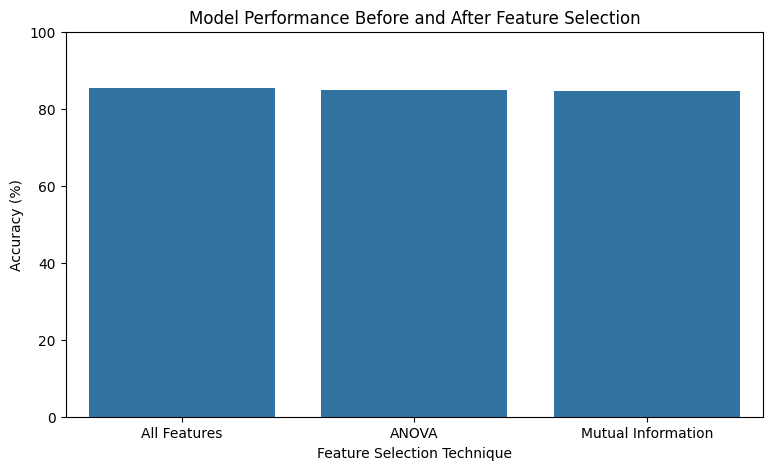

In [35]:
#Visualize model performance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy'
)

plt.title('Model Performance Before and After Feature Selection')
plt.xlabel('Feature Selection Technique')
plt.ylabel('Accuracy (%)')

plt.ylim(0, 100)

plt.show()

In [36]:
#Compare precision, recall and F1-score
#Accuracy alone may not tell us the complete performance of a classification model.

#comparing additional evaluation metrics.
from sklearn.metrics import f1_score, precision_score, recall_score

predictions = {
    'All Features': y_pred,
    'ANOVA': anova_pred,
    'Mutual Information': mi_pred
}

comparison = []

for name, pred in predictions.items():
    comparison.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(
            y_test, pred, pos_label='>50K'
        ),
        'Recall': recall_score(
            y_test, pred, pos_label='>50K'
        ),
        'F1 Score': f1_score(
            y_test, pred, pos_label='>50K'
        )
    })

comparison_df = pd.DataFrame(comparison)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,All Features,0.853221,0.739915,0.596491,0.660507
1,ANOVA,0.847588,0.728595,0.578947,0.645207
2,Mutual Information,0.845847,0.725352,0.572957,0.640210


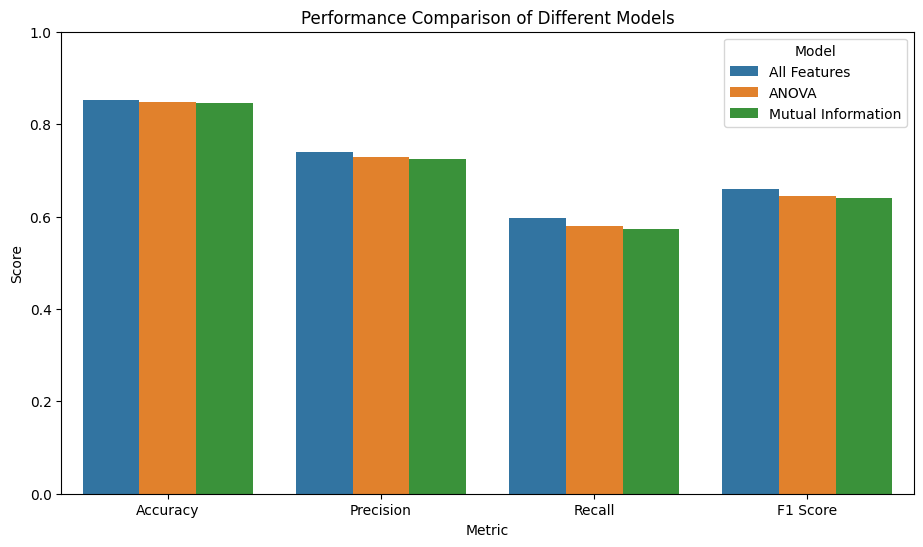

In [38]:
#Visualizing
comparison_melted = comparison_df.melt(
    id_vars='Model',
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_melted,
    x='Metric',
    y='Score',
    hue='Model'
)

plt.title('Performance Comparison of Different Models')
plt.ylim(0, 1)
plt.show()